# Science case: TDAMM follow-up (transient classification)

Time-domain and multi-messenger (TDAMM) follow-up with a spectrograph is mostly about
**classification**: a low-SNR spectrum, rebinned to R ~ 100-300, that distinguishes a SN Ia from a
SN II, a kilonova from an afterglow, or a TDE from an AGN flare. The relevant question for LFAST
is: *how faint a transient can we classify in a given exposure, and how quickly?*

**Assumptions used here** (knobs):

* Classification needs SNR ~ 5 per **rebinned** element at R_bin = 300 across 450-650 nm. In the
  photon-limited regime co-adding $k = R/R_{bin}$ resels raises SNR by $\sqrt{k}$; we use that
  approximation (it is exact when all noise terms scale with the number of pixels, which they do
  here except for the sqrt in the Howell formula, so it is slightly optimistic in the read-noise limit).
* Transient SEDs: a hot blue blackbody (12,000 K, young SN / shock cooling), a 6000 K blackbody
  (SN Ia near peak) and a cool red 3500 K blackbody (late kilonova / SN II late). A power-law
  $F_\nu \propto \nu^{-0.7}$ represents a GRB afterglow.
* Kilonova: AT2017gfo-like, peak $M_{r}$ ~ -16 at 40 Mpc gives r ~ 17 at peak, fading ~1 mag/day
  in the optical.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude
try:
    plt.style.use('gks')
except OSError:
    pass

In [2]:
bench = LFASTETC("bench_r1800", n_telescopes=20, wavelength_min_nm=450, wavelength_max_nm=650)
R_BIN = 300
k = bench.instrument.resolving_power / R_BIN   # resels per rebinned element
def snr_binned(res):
    return res.snr * np.sqrt(k)

seds = {"blue 12,000 K": Source.blackbody(12000, 0, "V"),
        "SN Ia-like 6000 K": Source.blackbody(6000, 0, "V"),
        "red 3500 K": Source.blackbody(3500, 0, "V"),
        "afterglow Fnu~nu^-0.7": Source.powerlaw(-0.7, 0, "V", system="AB")}

## Exposure time to classify versus magnitude

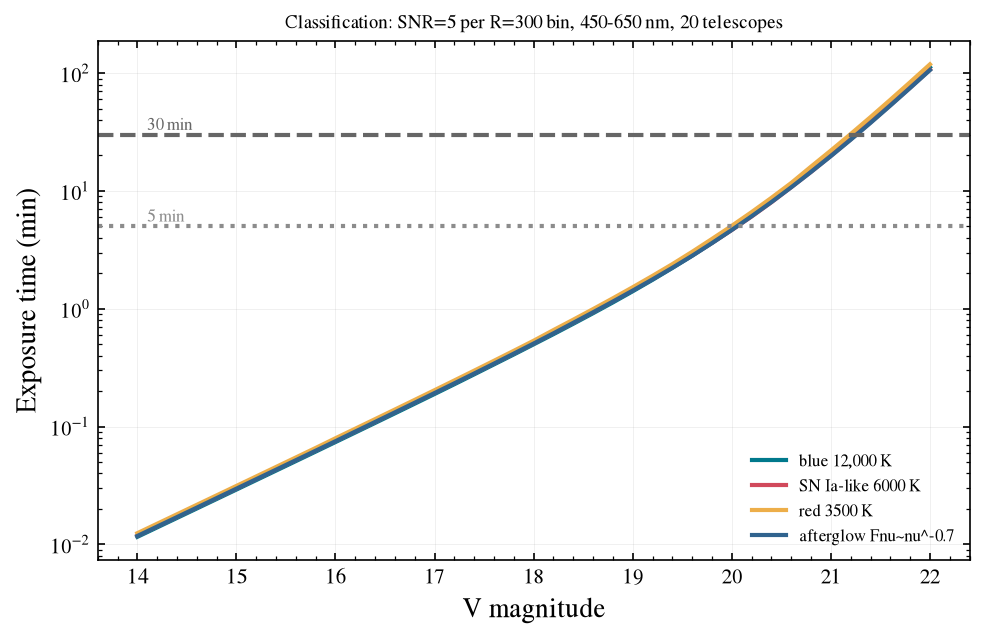

In [3]:
mags = np.linspace(14, 22, 41)
snr_resel_needed = 5 / np.sqrt(k)       # SNR per native resel that gives SNR=5 at R=300
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for label, src in seds.items():
    t = bench.exptime_vs_mag(src, mags, snr=snr_resel_needed, wavelength=(450, 650))
    ax.plot(mags, t/60, label=label)
ax.set_yscale('log'); ax.set_xlabel("V magnitude"); ax.set_ylabel("Exposure time (min)")
ax.axhline(30, color='0.4', ls='--'); ax.text(14.1, 33, "30 min", fontsize=8, color='0.4')
ax.axhline(5, color='0.55', ls=':'); ax.text(14.1, 5.5, "5 min", fontsize=8, color='0.55')
ax.legend(fontsize=8); ax.set_title(f"Classification: SNR=5 per R={R_BIN} bin, 450-650 nm, 20 telescopes", fontsize=9);

## Classification depth versus exposure time

In [4]:
for exp in (300, 900, 1800, 3600):
    lims = [f"{label}: V<{bench.limiting_magnitude(src, exp, snr_resel_needed, wavelength=(450, 650)):.1f}"
            for label, src in seds.items()]
    print(f"{exp:5d} s   " + " | ".join(lims))

  300 s   blue 12,000 K: V<20.0 | SN Ia-like 6000 K: V<20.1 | red 3500 K: V<20.0 | afterglow Fnu~nu^-0.7: V<20.1
  900 s   blue 12,000 K: V<20.8 | SN Ia-like 6000 K: V<20.8 | red 3500 K: V<20.8 | afterglow Fnu~nu^-0.7: V<20.8
 1800 s   blue 12,000 K: V<21.2 | SN Ia-like 6000 K: V<21.3 | red 3500 K: V<21.2 | afterglow Fnu~nu^-0.7: V<21.3
 3600 s   blue 12,000 K: V<21.6 | SN Ia-like 6000 K: V<21.7 | red 3500 K: V<21.6 | afterglow Fnu~nu^-0.7: V<21.7


## Kilonova: how many days after merger can we still classify?

AT2017gfo at 40 Mpc: r ~ 17.0 at 0.5 d, fading ~1 mag/day over the first few days while cooling
from ~10,000 K to ~3000 K (simple linear ramps used here). We scale to other distances with the
distance modulus and ask for a classification spectrum (SNR=5 at R=300) in a 30-minute exposure.

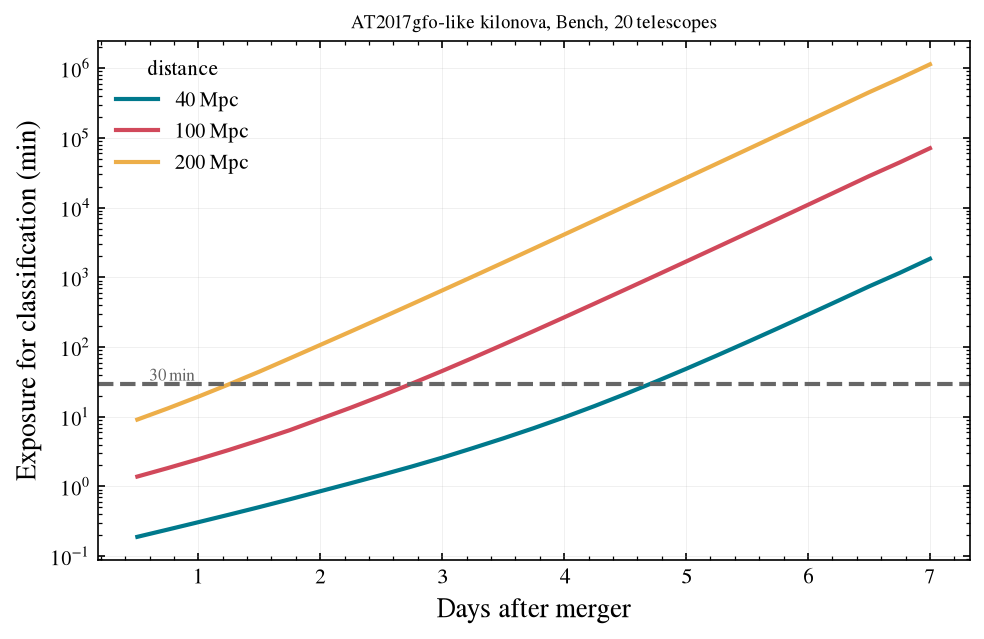

In [5]:
days = np.linspace(0.5, 7, 27)
def kn_mag(d, D_Mpc):
    return 17.0 + 1.0*(d-0.5) + 5*np.log10(D_Mpc/40)
def kn_teff(d):
    return np.interp(d, [0.5, 2, 7], [10000, 5000, 3000])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
for D in (40, 100, 200):
    t_needed = np.array([bench.exptime_vs_mag(Source.blackbody(kn_teff(d), 0, "V"), [kn_mag(d, D)],
                                              snr=snr_resel_needed, wavelength=(450, 650))[0] for d in days])
    ax.plot(days, t_needed/60, label=f"{D} Mpc")
ax.axhline(30, color='0.4', ls='--'); ax.text(0.6, 33, "30 min", fontsize=8, color='0.4')
ax.set_yscale('log'); ax.set_xlabel("Days after merger"); ax.set_ylabel("Exposure for classification (min)")
ax.legend(title="distance"); ax.set_title("AT2017gfo-like kilonova, Bench, 20 telescopes", fontsize=9);

## Rapid response: a fading afterglow

GRB afterglows fade as $F \propto t^{-\alpha}$ with $\alpha \sim 1$. For an afterglow at
R = 17 one hour after the burst, how does the time-to-classify grow with the delay before LFAST is
on target?

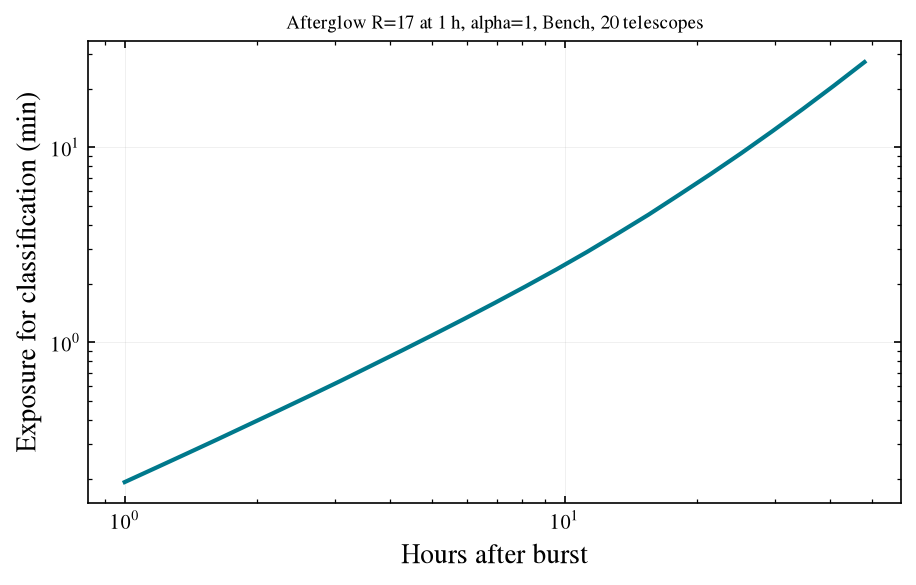

In [6]:
delay_h = np.logspace(0, np.log10(48), 25)
mag_t = 17 + 2.5*1.0*np.log10(delay_h/1.0)
t_cls = bench.exptime_vs_mag(seds["afterglow Fnu~nu^-0.7"], mag_t, snr=snr_resel_needed, wavelength=(450, 650))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(delay_h, t_cls/60)
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel("Hours after burst"); ax.set_ylabel("Exposure for classification (min)")
ax.set_title("Afterglow R=17 at 1 h, alpha=1, Bench, 20 telescopes", fontsize=9);

## Array size trade for TDAMM depth (30 min, classification SNR)

In [7]:
for n in (5, 10, 20, 40, 80):
    e = LFASTETC("bench_r1800", n_telescopes=n, wavelength_min_nm=450, wavelength_max_nm=650)
    print(f"N={n:3d}: classification depth in 30 min, 6000 K: V<{e.limiting_magnitude(seds['SN Ia-like 6000 K'], 1800, snr_resel_needed, wavelength=(450,650)):.2f}")

N=  5: classification depth in 30 min, 6000 K: V<20.35
N= 10: classification depth in 30 min, 6000 K: V<20.82
N= 20: classification depth in 30 min, 6000 K: V<21.25
N= 40: classification depth in 30 min, 6000 K: V<21.67
N= 80: classification depth in 30 min, 6000 K: V<22.07
